# 06-02 - Concepts and Scores

You read the masks a text-prompted model drew from one word on blocks it never saw, and score them against the volunteers and the model Lecture 05 trained.

We start with the word's masks over the held-out blocks and block 7 under six words. Then we choose the word on the validation blocks, score it on the test blocks beside the U-Net by pixel, chip and building, see where each wins and what shrinking costs, and score the open stand-in and a company's footprints.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import fm_tools as fm

plt.rcParams["figure.dpi"] = 72

scene = fm.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p06"]
torch_ok = fm.torch_available()
ready = {name: torch_ok and fm.model_ready(name) for name in ("sam2", "clip")}
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}; the open models are "
      f"{'ready' if all(ready.values()) else 'not loadable here, so the cells that run them are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready; the open models are ready


## The word over the window

The cell reads the text model's masks for the word building on the nine held-out blocks, counts the instances, and paints them on the window at 2.4 m.

the word 'building' through SAM 3: block 2 243, block 12 204, block 14 167, block 22 15, block 7 326, block 10 142, block 13 139, block 18 71, block 20 89 instances


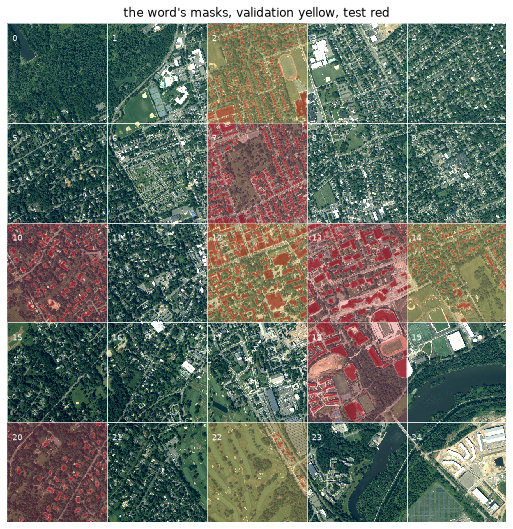

In [2]:
small, _ = fm.read_rgb("data/window_2m4.tif")
blocks = gpd.read_file("data/layers.gpkg", layer="blocks")
sam3 = fm.read_masks("data/masks_sam3.npz")
held, word = scene["val_blocks"] + scene["test_blocks"], scene["phrases"]["chosen"]
painted = np.zeros(small.shape[:2], dtype="float32")
for b in held:
    r0, c0 = (b // 5) * 256, (b % 5) * 256
    painted[r0:r0 + 256, c0:c0 + 256] = fm.downsample(fm.instances_at(sam3, fm.mask_key(word, b)) > 0, 8)
print(f"the word {word!r} through {scene['models']['sam3']['name']}: "
      + ", ".join(f"block {b} {fm.count_instances(sam3, fm.mask_key(word, b))}" for b in held) + " instances")
fig, ax = plt.subplots(figsize=(9, 9))
fm.show_window(ax, small, blocks, "the word's masks, validation yellow, test red", overlay=painted)

The lecture gave a text-prompted model one noun and nine blocks, the four validation and the five test blocks of Lecture 05, each in four tiles of 1,024 pixels so that a house keeps its 30 cm. Out came every instance of the concept, with no training on Princeton and no label of any block. Painted red at 2.4 m, the masks follow the streets of houses and leave the fields and the lake alone. The sixteen training blocks stay unpainted because the model never needed them.

## Block 7 under six words

The cell counts the instances the model found on block 7 under six different words and draws the crop of the block under each.

building 326, house 334, roof 322, car 264, tree 178, swimming pool 1 instances; 338 footprints have their centre in the block
reference building 326, house 334, roof 322, car 264, tree 178, swimming pool 1


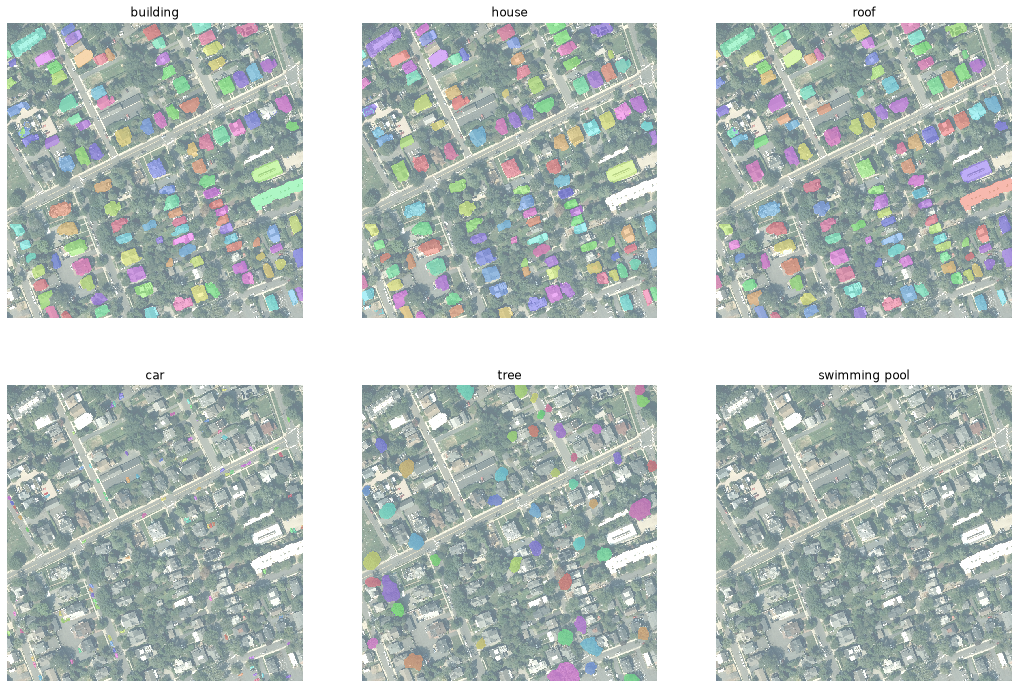

In [3]:
image7, tr7, crs7, res7 = fm.read_raster("data/block_7.tif")
picture7 = fm.stretch(image7)
qr, qc = scene["prompt"]["crop_origin"]
win = (slice(qr, qr + scene["prompt"]["crop_px"]), slice(qc, qc + scene["prompt"]["crop_px"]))
shown = scene["phrases"]["shown"]
counts7 = {ph: fm.count_instances(sam3, fm.mask_key(ph, 7)) for ph in shown}
print(", ".join(f"{ph} {n}" for ph, n in counts7.items())
      + f" instances; {scene['block']['footprints']} footprints have their centre in the block")
print("reference " + ", ".join(f"{ph} {reference['text']['block7_counts'][ph]['instances']}" for ph in shown))
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, ph in zip(axes.ravel(), shown):
    fm.show_instances(ax, picture7[win], fm.instances_at(sam3, fm.mask_key(ph, 7))[win], ph)

The word is the prompt, and the word matters. Building, house and roof find nearly the same three hundred objects, car finds the cars in the driveways, tree the crowns, and swimming pool one pool in the whole block. Look at the crop under roof against building: the model draws the roof plane where the picture shows one and the whole house where the word asks for it. A concept is what the model learned the word to mean, and your phrasing picks which concept you get.

## The word chosen on the validation blocks

The cell reads the masks of the nine blocks, scores three words on the four validation blocks alone, and chooses the best.

In [4]:
masks = {b: fm.read_raster(f"data/mask_{b}.tif")[0] > 0 for b in held}
val, test, scored = scene["val_blocks"], scene["test_blocks"], scene["phrases"]["scored"]
on_val = {}
for ph in scored:
    preds = [fm.instances_at(sam3, fm.mask_key(ph, b)) > 0 for b in val]
    on_val[ph] = fm.pooled_metrics(preds, [masks[b] for b in val])["iou"]
chosen = fm.choose_phrase(on_val)
print("IoU on the four validation blocks: " + ", ".join(f"{ph} {v:.3f}" for ph, v in on_val.items()))
print("reference " + ", ".join(f"{ph} {reference['text']['validation_iou'][ph]}" for ph in scored))
print(f"the word chosen before any test block is looked at: {chosen!r}")

IoU on the four validation blocks: building 0.666, house 0.469, roof 0.612
reference building 0.6662, house 0.4685, roof 0.6121
the word chosen before any test block is looked at: 'building'


Three words were tried, and the choice between them is a decision, so it is made on the validation blocks and never on the test blocks, exactly as the lecture chose the epoch to stop at. Building wins by five points over roof and by twenty over house, because the volunteers drew whole buildings and the word house makes the model skip garages, sheds and larger blocks of flats. The number printed next is the one the test blocks may see, fixed before they were opened.

## The test blocks, by pixel

The cell scores the chosen word on the five test blocks pooled, beside the U-Net of Lecture 05 on the same pixels, and prints the IoU block by block.

In [5]:
unet = {b: fm.read_raster(f"data/unet_{b}.tif")[0] >= 128 for b in test}
word_masks = {b: fm.instances_at(sam3, fm.mask_key(chosen, b)) > 0 for b in test}
pw = fm.pooled_metrics([word_masks[b] for b in test], [masks[b] for b in test])
pu = fm.pooled_metrics([unet[b] for b in test], [masks[b] for b in test])
rt, ru = reference["text"]["test"], reference["unet"]["test"]
print(f"the word {chosen!r}, no Princeton label: IoU {pw['iou']:.3f}, precision {pw['precision']:.3f}, "
      f"recall {pw['recall']:.3f}   reference {rt['iou']}, {rt['precision']}, {rt['recall']}")
print(f"the U-Net, 1,024 labelled chips: IoU {pu['iou']:.3f}, precision {pu['precision']:.3f}, "
      f"recall {pu['recall']:.3f}   reference {ru['iou']}, {ru['precision']}, {ru['recall']}")
per = {b: (fm.iou(word_masks[b], masks[b]), fm.iou(unet[b], masks[b])) for b in test}
print("block by block, the word against the U-Net: "
      + ", ".join(f"{b} {w:.2f} vs {u:.2f}" for b, (w, u) in per.items()))

the word 'building', no Princeton label: IoU 0.658, precision 0.783, recall 0.804   reference 0.6576, 0.7827, 0.8044
the U-Net, 1,024 labelled chips: IoU 0.681, precision 0.820, recall 0.801   reference 0.6813, 0.82, 0.801
block by block, the word against the U-Net: 7 0.70 vs 0.74, 10 0.55 vs 0.62, 13 0.73 vs 0.68, 18 0.63 vs 0.69, 20 0.52 vs 0.58


This is the lecture's headline. A model that never saw a Princeton label reaches an overlap within two points of the model that trained on a thousand labelled chips, on the same pixels and against the same referee. Its recall is higher, it finds more of the roof, and its precision lower, it paints a little beyond. Block by block the picture is mixed: the U-Net wins the dense residential blocks it was trained for, the word wins the block with the large campus buildings. One number hides this.

## Chip by chip

The cell scores every test chip on its own for the word and for the U-Net, and averages the chips that hold a roof or a prediction.

In [6]:
rows_w = [r for b in test for r in fm.chip_scores(word_masks[b], masks[b])[0]]
rows_u = [r for b in test for r in fm.chip_scores(unet[b], masks[b])[0]]
mean_w = np.mean([r["iou"] for r in rows_w if r["iou"] is not None])
mean_u = np.mean([r["iou"] for r in rows_u if r["iou"] is not None])
rt, ru = reference["text"], reference["unet"]
print(f"chip by chip on the centre-kept maps: the word {mean_w:.3f}, the U-Net {mean_u:.3f}"
      f"   reference {rt['chip_mean']} and {ru['chip_mean']}; "
      f"the lecture's tiled chips {ru['lecture']['iou_chip']}")
print(f"pooled over the same pixels: the word {pw['iou']:.3f}, the U-Net {pu['iou']:.3f}")

chip by chip on the centre-kept maps: the word 0.581, the U-Net 0.611   reference 0.5807 and 0.6109; the lecture's tiled chips 0.663
pooled over the same pixels: the word 0.658, the U-Net 0.681


Precept 05 taught that a chip-by-chip average sits below the pooled number, and it does here for both models, because a chip with one small shed can score near zero and counts as much as a chip full of roofs. The lecture's 0.663 for the U-Net came from the chips predicted one by one with seams; the centre-kept map scores lower chip by chip and higher pooled. Two averages of the same pixels, two numbers; a poster says which one it reports.

## Building by building

The cell burns the footprints that touch each test block onto its grid, matches the predicted blobs to them at an overlap of one half, and counts.

buildings matched at an overlap of one half: the word 453, the U-Net 478, of 699 footprints   reference 453, 478


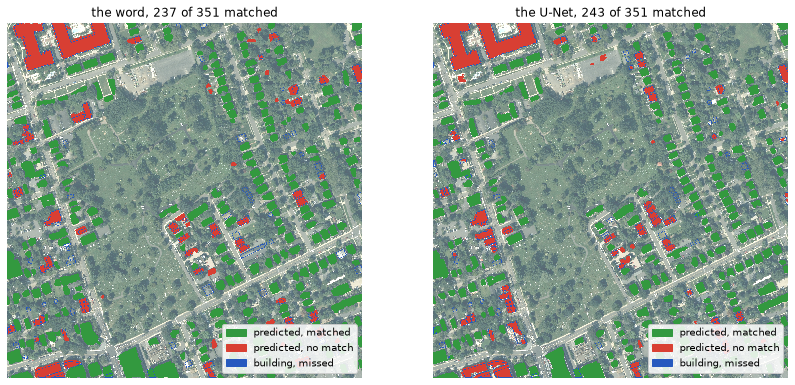

In [7]:
ids = {b: fm.footprint_ids(b) for b in test}
objs_w = {b: fm.match_objects(word_masks[b], ids[b]) for b in test}
objs_u = {b: fm.match_objects(unet[b], ids[b]) for b in test}
mw, mu = sum(o["matched"] for o in objs_w.values()), sum(o["matched"] for o in objs_u.values())
n_ref = sum(o["reference"] for o in objs_w.values())
print(f"buildings matched at an overlap of one half: the word {mw}, the U-Net {mu}, of {n_ref} footprints"
      f"   reference {reference['text']['objects']['matched']}, {reference['unet']['objects']['matched']}")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
ow7, ou7 = objs_w[7], objs_u[7]
fm.show_objects(axes[0], picture7, ow7, ids[7], f"the word, {ow7['matched']} of {ow7['reference']} matched")
fm.show_objects(axes[1], picture7, ou7, ids[7], f"the U-Net, {ou7['matched']} of {ou7['reference']} matched")

Building by building, a predicted blob counts when it overlaps one footprint by at least half, each footprint matched once, the rule of Precept 05. The reference is every footprint that touches a block, 351 on block 7, a few more than the 338 whose centre lies in it. The word matches fewer buildings than the U-Net although it finds more roof pixels, because it merges some neighbours and splits some houses. The pictures show block 7 with the matched blobs in green and the missed buildings outlined in blue.

## Where each wins

The cell finds the chip of block 7 where the word beats the U-Net by most, and the chip where the U-Net beats the word by most, and draws both.

of 53 chips of block 7 with a roof, the word wins most at row 0, column 768 by 0.61 to 0.47 (reference 0.6083 to 0.4708); the U-Net at row 1536, column 1024 by 0.75 to 0.55


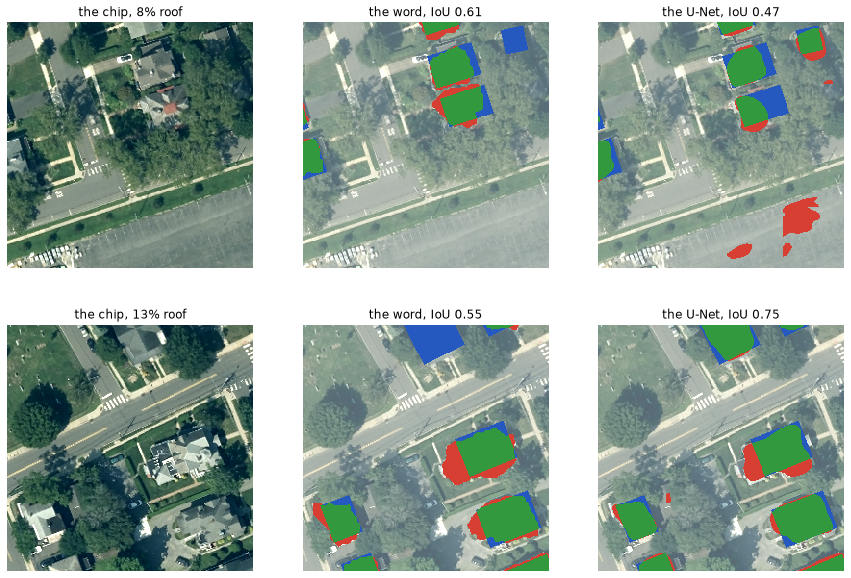

In [8]:
chips, origin = fm.chip_table("data/chips.csv"), tuple(scene["block"]["origin"])
ww, uw, n_chips = fm.where_each_wins(word_masks[7], unet[7], masks[7], fm.block_chips(chips, 7), origin)
rw = reference["text"]["where_each_wins"]["word"]
print(f"of {n_chips} chips of block 7 with a roof, the word wins most at row {ww['row']}, column {ww['col']} "
      f"by {ww['word']:.2f} to {ww['unet']:.2f} (reference {rw['word']} to {rw['unet']}); the U-Net at row "
      f"{uw['row']}, column {uw['col']} by {uw['unet']:.2f} to {uw['word']:.2f}")
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for row, c in zip(axes, (ww, uw)):
    sl = (slice(c["row"], c["row"] + 256), slice(c["col"], c["col"] + 256))
    fm.show_image(row[0], picture7[sl], f"the chip, {c['share']:.0%} roof")
    fm.show_agreement(row[1], word_masks[7][sl], masks[7][sl], picture7[sl], f"the word, IoU {c['word']:.2f}")
    fm.show_agreement(row[2], unet[7][sl], masks[7][sl], picture7[sl], f"the U-Net, IoU {c['unet']:.2f}")

Two chips, two winners. On the upper chip the word separates touching houses and finds a shed the volunteers drew, where the U-Net merged neighbours into one blob. On the lower chip the U-Net covers every roof it was trained to see, and the word stops at a roof plane and misses an addition under the trees. Green is roof found, red a false alarm, blue roof missed. Neither model is better; each has habits, and a project chooses by what it needs to count or measure.

## The block shrunk to the model's input

The cell reads the pass that handed the model the whole block at once, shrunk to its input size, and compares it with the tiled pass.

the whole block at once: 32 instances, IoU 0.218   reference 32 and 0.2178
the block in four tiles: 326 instances, IoU 0.698


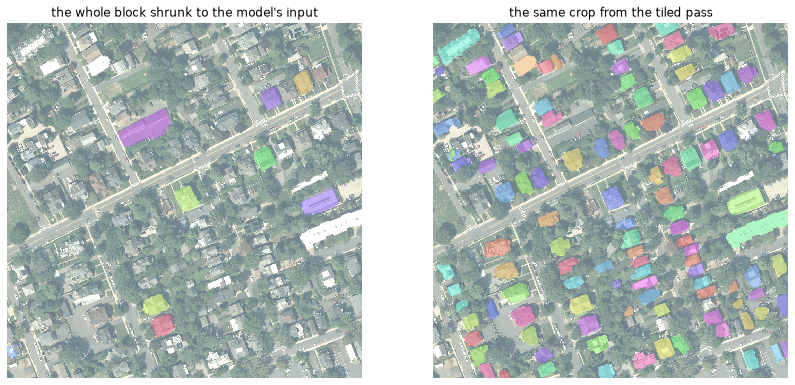

In [9]:
shrunk = fm.instances_at(sam3, fm.mask_key(chosen, 7, resized=True))
tiled = fm.instances_at(sam3, fm.mask_key(chosen, 7))
rz = reference["text"]["block7_resized"]
print(f"the whole block at once: {fm.count_instances(sam3, fm.mask_key(chosen, 7, resized=True))} instances, "
      f"IoU {fm.iou(shrunk > 0, masks[7]):.3f}   reference {rz['instances']} and {rz['iou']}")
print(f"the block in four tiles: {fm.count_instances(sam3, fm.mask_key(chosen, 7))} instances, "
      f"IoU {fm.iou(tiled > 0, masks[7]):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fm.show_instances(axes[0], picture7[win], shrunk[win], "the whole block shrunk to the model's input")
fm.show_instances(axes[1], picture7[win], tiled[win], "the same crop from the tiled pass")

The model reads a picture of about a thousand pixels a side. Handed the whole block, two thousand pixels and 614 m, it shrinks it by half, a house becomes a few dozen pixels, and the model finds a tenth of the buildings and a third of the overlap. Cut into four tiles at the full 30 cm it finds them all. Resolution is not a detail of the data pipeline; it is the difference between a model that works and one that does not.

## The open stand-in

The cell reads the masks of the open stand-in, a detector that turns a word into boxes and the open segment-anything model that turns boxes into masks, and scores them.

the stand-in's word 'house' at a detector score of 0.2, chosen on the validation blocks, where it scored 0.503 against building's 0.3125
on the test blocks: IoU 0.457, precision 0.538, recall 0.753   reference 0.4571, 0.5379, 0.7528


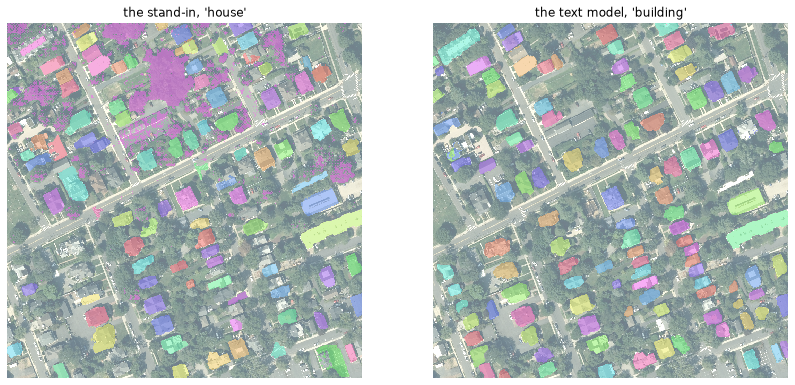

In [10]:
open_ = fm.read_masks("data/masks_open.npz")
ow, ot, ro = scene["phrases"]["open_phrase"], scene["phrases"]["open_threshold"], reference["open"]
preds = [fm.instances_at(open_, fm.mask_key(ow, b), ot) > 0 for b in test]
po = fm.pooled_metrics(preds, [masks[b] for b in test])
print(f"the stand-in's word {ow!r} at a detector score of {ot}, chosen on the validation blocks, where it "
      f"scored {ro['validation_iou'][ow]} against building's {ro['validation_iou']['building']}")
print(f"on the test blocks: IoU {po['iou']:.3f}, precision {po['precision']:.3f}, recall {po['recall']:.3f}"
      f"   reference {ro['test']['iou']}, {ro['test']['precision']}, {ro['test']['recall']}")
stand = fm.instances_at(open_, fm.mask_key(ow, 7), ot)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fm.show_instances(axes[0], picture7[win], stand[win], f"the stand-in, '{ow}'")
fm.show_instances(axes[1], picture7[win], tiled[win], f"the text model, '{chosen}'")

The text model's weights are gated, so the kit cannot run it and ships its masks. The open lane is two models in a row, Grounding DINO for the boxes and SAM 2.1 for the masks, both Apache 2.0 and downloadable by anyone. It reaches two thirds of the text model's overlap, with the word house, and its boxes merge neighbouring houses and cut others in two. To run it yourself, load both models through the transformers library as 06-01 did; the detector's weights are not in the container.

## A company's footprints

The cell reads the building footprints a company mapped with its own model for the whole country, cut to block 7, and scores them against the volunteers like any mask.

330 footprints from the company's model against the volunteers' 358: IoU 0.720, 288 matched at one half   reference 0.7202, 288


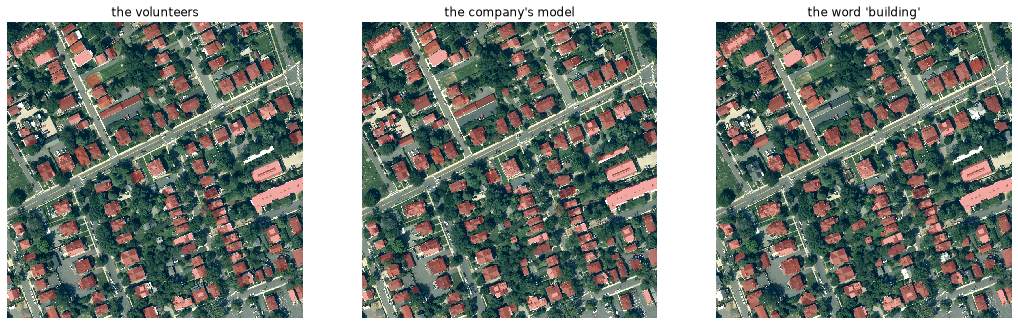

In [11]:
company = gpd.read_file("data/layers.gpkg", layer="footprints_7_company")
cids = fm.rasterise(company, tr7, masks[7].shape)
pc = fm.pixel_metrics(fm.confusion(cids > 0, masks[7]))
oc = fm.match_objects(cids > 0, ids[7])
rc = reference["text"]["company"]
print(f"{len(company)} footprints from the company's model against the volunteers' "
      f"{rc['volunteers_touching']}: IoU {pc['iou']:.3f}, {oc['matched']} matched at one half"
      f"   reference {rc['iou']}, {rc['matched']}")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fm.show_mask(axes[0], picture7[win], masks[7][win], "the volunteers", alpha=0.45)
fm.show_mask(axes[1], picture7[win], (cids > 0)[win], "the company's model", alpha=0.45)
fm.show_mask(axes[2], picture7[win], word_masks[7][win], f"the word '{chosen}'", alpha=0.45)

Lecture 01 promised these footprints: a company ran a building model over every aerial photograph of the country and published the polygons. On block 7 they agree with the volunteers about as well as the trained U-Net does, and better than the word, which is what a model tuned on millions of buildings should reach. They are a dataset to use, with their vintage and licence stated, not a truth; the volunteers are not a truth either, only the referee this course agreed on in Lecture 05.

## Your turn

The word was chosen on the validation blocks, where house lost to building by twenty points. See what the test blocks say about the word house. Run the cell as it is, then change the marked value and run it again.

Did the test blocks rank the two words as the validation blocks did, and which block fell furthest? What in that block's picture explains the fall? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [12]:
PHRASE = "building"  # change me: "house"
masks_phrase = {b: fm.instances_at(sam3, fm.mask_key(PHRASE, b)) > 0 for b in test}
pp = fm.pooled_metrics([masks_phrase[b] for b in test], [masks[b] for b in test])
print(f"the word {PHRASE!r} on the five test blocks: IoU {pp['iou']:.3f}, precision {pp['precision']:.3f}, "
      f"recall {pp['recall']:.3f}")
print("block by block: " + ", ".join(f"{b} {fm.iou(masks_phrase[b], masks[b]):.2f}" for b in test))

the word 'building' on the five test blocks: IoU 0.658, precision 0.783, recall 0.804
block by block: 7 0.70, 10 0.55, 13 0.73, 18 0.63, 20 0.52


## Check your understanding

1. The word was chosen on the validation blocks and scored on the test blocks. What would go wrong with the headline number if the choice had been made on the test blocks?
2. The word's recall is higher than the U-Net's and its precision lower. Which would a project that counts buildings prefer, and which a project that measures roof area?
3. Shrinking the block to the model's input lost most of the buildings. How does this change the pipeline you would write for a whole town?
4. The company's footprints beat the word and tie the U-Net. What must a poster state when it uses them?

## Where we are

You have read the masks a word drew on nine blocks the model never saw, chosen the word honestly, scored it by pixel, by chip and by building against the volunteers and the trained model, seen the two chips where each wins, learned what resolution costs, and set the open stand-in and a company's footprints beside it. You now know what a text prompt buys, what it does not, and how to report it. In 06-03 a model names a picture in words, and another answers questions about it.

## Further resources

Nothing in this course requires anything below.

- GeoAI with Python, chapter 14 on the Segment Anything models, Qiusheng Wu, 2026, https://geoai.gishub.org
- SAM 3: Segment Anything with Concepts, Nicolas Carion and colleagues, 2025, https://arxiv.org/abs/2511.16719
- Grounding DINO, Shilong Liu and colleagues, ECCV 2024, https://arxiv.org/abs/2303.05499
- Microsoft Global ML Building Footprints, https://github.com/microsoft/GlobalMLBuildingFootprints

The masks, numbers and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. The footprints are an OpenStreetMap extract, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright SAM 2.1 (Meta) is released under the Apache 2.0 licence, CLIP ViT-B/16 (OpenAI) under the MIT licence. The masks of the text model are outputs of SAM 3 (Meta), whose gated weights are released under the SAM License of 19 November 2025; that licence governs the distribution of the model and of works derived from it and asks that research using it acknowledge the use, which this kit does, and it says nothing that restricts its outputs, so the masks ship as the course's own work. The weights never ship, and the open stand-in (Grounding DINO tiny, IDEA Research, and SAM 2.1, both Apache 2.0) is the kit's live text lane.